In [43]:
#@title Setup (run this first)
!pip install -q pystac-client planetary-computer rioxarray

import pandas as pd
import matplotlib.pyplot as plt
import pystac_client, planetary_computer, rioxarray
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from google.colab import files
from IPython.display import HTML, display

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace)

print("Setup complete.")

def stop(message):
    display(HTML(
        '<div style="background:#fde2e1; color:#8a1c1c; border-left:6px solid #d93025; '
        'padding:12px 16px; font-size:15px; border-radius:4px;">'
        f'<b>⚠️ Please check your settings:</b> {message}</div>'))
    raise ValueError(message)

Setup complete.


In [44]:
#@title Settings: choose your area and years
#@markdown **Area:** a box in degrees. To find coordinates, right-click a point in Google Maps. It shows *latitude, longitude*: latitude is north/south, longitude is east/west.
#@markdown
#@markdown **Years:** the first year must be 2017 or later (the data starts in 2017), and the second must be later than the first. Run this cell to see every year available for your area, listed below it.
place_name = "Ravi River near Lahore"  #@param {type:"string"}
west = 74.18  #@param {type:"number"}
south = 31.52  #@param {type:"number"}
east = 74.40  #@param {type:"number"}
north = 31.72  #@param {type:"number"}
year_before = 2017  #@param {type:"integer"}
year_after = 2023  #@param {type:"integer"}

bbox = [west, south, east, north]
years = [year_before, year_after]

if not (west < east and south < north):
    stop("West must be less than east, and south less than north.")
if (east - west) > 0.5 or (north - south) > 0.5:
    stop("Area too large: keep each side under 0.5 degrees (about 50 km).")
if not 2017 <= year_before < year_after:
    stop("year_before must be 2017 or later, and year_after must be later than year_before.")

all_items = catalog.search(collections=["io-lulc-annual-v02"], bbox=bbox).items()
available = sorted({int(item.id.split("-")[-1]) for item in all_items})
print("Years available for this area:", available)

for year in years:
    if year not in available:
        stop(f"No land cover data for {year} here. Choose from: {available}")

print(f"Settings OK: {place_name}, {year_before} vs {year_after}")


Years available for this area: [2017, 2018, 2019, 2020, 2021, 2022, 2023]
Settings OK: Ravi River near Lahore, 2017 vs 2023


In [45]:
items_by_year = {}
for year in years:
    search = catalog.search(collections=["io-lulc-annual-v02"], bbox=bbox,
                            datetime=f"{year}-01-01/{year}-12-31")
    matches = [item for item in search.items() if item.id.endswith(str(year))]
    if len(matches) == 0:
        stop(f"No land cover data found for {year} in this area.")
    if len(matches) > 1:
        stop(f"Your area crosses a tile boundary ({[m.id for m in matches]}). "
                         "Move or shrink the box so it fits inside one tile.")
    items_by_year[year] = matches[0]
    print(year, "→", matches[0].id)

2017 → 43R-2017
2023 → 43R-2023


In [46]:
lulc = {}
for year, item in items_by_year.items():
    raster = rioxarray.open_rasterio(item.assets["data"].href)
    lulc[year] = raster.rio.clip_box(*bbox, crs="EPSG:4326")
    lulc[year].rio.to_raster(f"lulc_{year}.tif", compress="deflate")
    print(year, lulc[year].shape, lulc[year].rio.crs)

2017 (1, 2232, 2102) EPSG:32643
2023 (1, 2232, 2102) EPSG:32643


In [47]:
present = set()
for year in years:
    counts = pd.Series(lulc[year].values.ravel()).value_counts().sort_index()
    present.update(counts.index)
    print(year, counts.to_dict())

if lulc[year_before].rio.transform() != lulc[year_after].rio.transform():
    stop("The two years are not on the same grid, so they can't be compared.")
print("Same grid: OK")

if 0 in present:
    print("Note: some pixels have no data (class 0). They are left out of the change table.")

2017 {1: 105208, 2: 4952, 4: 80, 5: 2256320, 7: 2092407, 8: 110277, 11: 122420}
2023 {1: 115721, 2: 18240, 4: 39, 5: 2059923, 7: 2341396, 8: 36755, 11: 119590}
Same grid: OK


In [48]:
classes = {
    1: ("Water", "#419bdf"),
    2: ("Trees", "#397d49"),
    4: ("Flooded vegetation", "#7a87c6"),
    5: ("Crops", "#e49635"),
    7: ("Built area", "#c4281b"),
    8: ("Bare ground", "#a59b8f"),
    9: ("Snow/ice", "#a8ebff"),
    10: ("Clouds", "#616161"),
    11: ("Rangeland", "#e3e2c3"),
}

codes = list(classes)
cmap = ListedColormap([classes[c][1] for c in codes])
cmap.set_under("white")
norm = BoundaryNorm([c - 0.5 for c in codes] + [codes[-1] + 0.5], cmap.N)

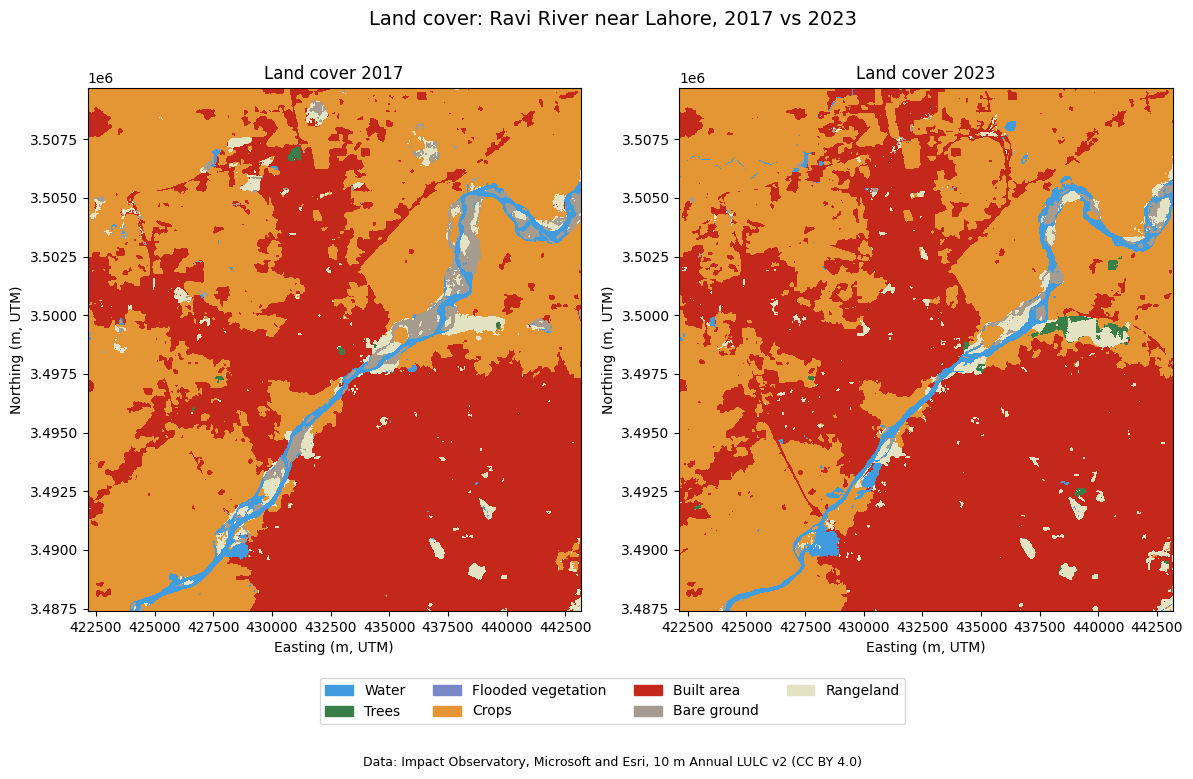

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, year in zip(axes, years):
    lulc[year].squeeze().plot.imshow(ax=ax, cmap=cmap, norm=norm, add_colorbar=False)
    ax.set_title(f"Land cover {year}")
    ax.set_xlabel("Easting (m, UTM)")
    ax.set_ylabel("Northing (m, UTM)")
    ax.set_aspect("equal")

legend = [Patch(color=colour, label=name)
          for code, (name, colour) in classes.items() if code in present]
fig.legend(handles=legend, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.05))
fig.suptitle(f"Land cover: {place_name}, {year_before} vs {year_after}", fontsize=14)
fig.text(0.5, -0.1, "Data: Impact Observatory, Microsoft and Esri, 10 m Annual LULC v2 (CC BY 4.0)",
         ha="center", fontsize=9)

map_file = f"landcover_{year_before}_{year_after}.png"
plt.savefig(map_file, dpi=200, bbox_inches="tight")
plt.show()

In [50]:
col_from, col_to = f"from_{year_before}", f"to_{year_after}"

before = lulc[year_before].values.ravel()
after = lulc[year_after].values.ravel()
valid = (before != 0) & (after != 0)

names = {code: name for code, (name, colour) in classes.items()}
change = pd.crosstab(before[valid], after[valid], rownames=[col_from], colnames=[col_to]) / 100
change = change.rename(index=names, columns=names).round(1)
change

to_2023,Water,Trees,Flooded vegetation,Crops,Built area,Bare ground,Rangeland
from_2017,,,,,,,
Water,479.9,0.8,0.1,324.4,26.0,110.0,110.8
Trees,0.0,6.3,0.0,2.0,35.0,0.0,6.2
Flooded vegetation,0.1,0.0,0.3,0.0,0.0,0.0,0.4
Crops,257.9,74.0,0.0,19185.5,2645.4,77.1,323.3
Built area,12.8,13.9,0.0,334.0,20396.6,10.9,155.8
Bare ground,288.3,0.5,0.0,375.6,78.6,139.1,220.7
Rangeland,118.2,86.9,0.0,377.8,232.3,30.5,378.6


In [51]:
pairs = change.reset_index().melt(id_vars=col_from, var_name=col_to, value_name="hectares")
conversions = pairs[pairs[col_from] != pairs[col_to]]
conversions = conversions.sort_values("hectares", ascending=False).head(10)
conversions

,from_2017,to_2023,hectares
31,Crops,Built area,2645.4
27,Rangeland,Crops,377.8
26,Bare ground,Crops,375.6
25,Built area,Crops,334.0
21,Water,Crops,324.4
45,Crops,Rangeland,323.3
5,Bare ground,Water,288.3
3,Crops,Water,257.9
34,Rangeland,Built area,232.3
47,Bare ground,Rangeland,220.7


In [52]:
matrix_file = f"change_matrix_{year_before}_{year_after}_ha.csv"
top_file = f"top_conversions_{year_before}_{year_after}_ha.csv"

change.to_csv(matrix_file)
conversions.to_csv(top_file, index=False)

for f in [map_file, matrix_file, top_file]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>